# Member 4 — Status, Timestamp & Shipping-Duration Validation

Run from the repository root or the `notebooks` directory. The notebook locates `data/raw/DataCoSupplyChainDataset.csv` by searching the current directory and its parents. It preserves the raw file and does not drop repeated Order IDs.

In [15]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
SOURCE_NAME = 'DataCoSupplyChainDataset.csv'
ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'data' / 'raw' / SOURCE_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Could not locate data/raw/{SOURCE_NAME} from {Path.cwd()} or its parent directories."
    )
SOURCE = ROOT / 'data' / 'raw' / SOURCE_NAME
OUT = ROOT / 'data' / 'interim'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
for p in (OUT, REPORTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(SOURCE, encoding='latin1', low_memory=False)
print('Project root:', ROOT)
print('Source shape:', df.shape)
df.head(10)

Project root: q:\Family Data\Data analyst\ecommerce-logistics-analysis
Source shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:42,First Class
7,TRANSFER,2,1,68.430000,285.140015,Late delivery,1,73,Sporting Goods,Miami,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:21,First Class
8,CASH,3,2,133.720001,278.589996,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 10:00,Second Class
9,CASH,2,1,132.149994,275.309998,Late delivery,1,73,Sporting Goods,San Ramon,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 9:39,First Class


In [16]:
date_cols=['order date (DateOrders)','shipping date (DateOrders)']
parsed={c:pd.to_datetime(df[c],errors='coerce') for c in date_cols}
order_dt,ship_dt=parsed[date_cols[0]],parsed[date_cols[1]]
real=pd.to_numeric(df['Days for shipping (real)'],errors='coerce')
sched=pd.to_numeric(df['Days for shipment (scheduled)'],errors='coerce')
delta=(ship_dt-order_dt).dt.total_seconds()/86400
checks=[]
def ck(area,metric,result,assessment='INFO',notes=''): checks.append({'Check':area,'Metric':metric,'Result':result,'Assessment':assessment,'Notes':notes})
ck('Integrity','Rows',len(df)); ck('Integrity','Columns',len(df.columns))
ck('Duplicates','Exact duplicate rows',int(df.duplicated().sum()),'PASS' if not df.duplicated().any() else 'REVIEW')
ck('Identifiers','Distinct Order Id',int(df['Order Id'].nunique()),'INFO','Repeated Order Id is not an automatic duplicate.')
ck('Identifiers','Distinct Order Item Id',int(df['Order Item Id'].nunique()),'PASS' if df['Order Item Id'].is_unique else 'REVIEW')
for c,d in parsed.items(): ck('Timestamps',f'Invalid/missing {c}',int(d.isna().sum()),'PASS' if d.notna().all() else 'REVIEW')
ck('Timestamps','Shipping before order',int((ship_dt<order_dt).sum()),'PASS' if not (ship_dt<order_dt).any() else 'REVIEW')
ck('Duration','Missing/non-numeric actual',int(real.isna().sum()),'PASS' if real.notna().all() else 'REVIEW')
ck('Duration','Negative actual',int((real<0).sum()),'PASS' if not (real<0).any() else 'REVIEW')
ck('Duration','Actual range',f'{real.min()} to {real.max()} days')
ck('Duration','Missing/non-numeric scheduled',int(sched.isna().sum()),'PASS' if sched.notna().all() else 'REVIEW')
ck('Duration','Negative scheduled',int((sched<0).sum()),'PASS' if not (sched<0).any() else 'REVIEW')
ck('Duration','Scheduled range',f'{sched.min()} to {sched.max()} days')
ck('Cross-check','Floor timestamp delta differs from supplied actual duration',int((np.floor(delta)!=real).sum()),'REVIEW','Confirm definition/rounding before modifying supplied duration.')
for c in ['Order Status','Delivery Status','Shipping Mode']:
 s=df[c].dropna().astype(str); n=int((s!=s.str.strip()).sum())
 ck('Text validation',f'Whitespace values in {c}',n,'PASS' if n==0 else 'REVIEW')
 ck('Text validation',f'Distinct labels in {c}',int(s.nunique()))
for c in ['Order Status','Delivery Status']:
 n=int(df.groupby('Order Id')[c].nunique().gt(1).sum()); ck('Status consistency',f'Order IDs with multiple {c} values',n,'PASS' if n==0 else 'REVIEW')
pd.DataFrame(checks).to_csv(REPORTS/'Member4_Cleaning_Validation_Audit.csv',index=False)
pd.DataFrame(checks)

,Check,Metric,Result,Assessment,Notes
0,Integrity,Rows,180519,INFO,
1,Integrity,Columns,53,INFO,
2,Duplicates,Exact duplicate rows,0,PASS,
3,Identifiers,Distinct Order Id,65752,INFO,Repeated Order Id is not an automatic duplicate.
4,Identifiers,Distinct Order Item Id,180519,PASS,
5,Timestamps,Invalid/missing order date (DateOrders),0,PASS,
6,Timestamps,Invalid/missing shipping date (DateOrders),0,PASS,
7,Timestamps,Shipping before order,0,PASS,
8,Duration,Missing/non-numeric actual,0,PASS,
9,Duration,Negative actual,0,PASS,


## Conservative cleaning

Only standardize timestamp strings and strip outer whitespace from status/mode text. No rows are dropped, no values imputed, and no business labels are recoded because no approved rules were provided.

In [17]:
clean=df.copy()
for c in ['Order Status','Delivery Status','Shipping Mode']: clean[c]=clean[c].astype('string').str.strip()
for c in date_cols: clean[c]=pd.to_datetime(clean[c],errors='coerce').dt.strftime('%Y-%m-%d %H:%M:%S')
assert clean.shape==df.shape
clean.to_csv(OUT/'DataCoSupplyChain_M4_cleaned_interim.csv',index=False,encoding='utf-8')
print('Raw and interim shapes:',df.shape,clean.shape)

Raw and interim shapes: (180519, 53) (180519, 53)


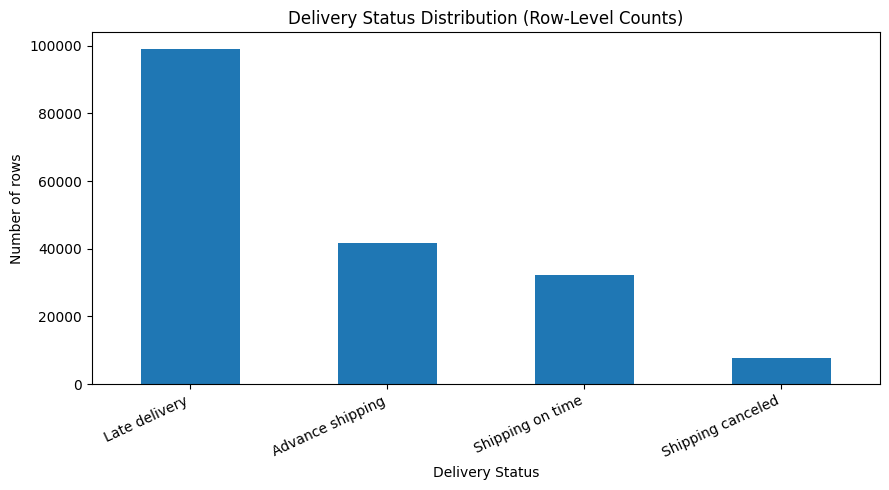

In [18]:
counts=df['Delivery Status'].value_counts()
ax=counts.plot(kind='bar',figsize=(9,5),title='Delivery Status Distribution (Row-Level Counts)')
ax.set_xlabel('Delivery Status'); ax.set_ylabel('Number of rows'); plt.xticks(rotation=25,ha='right'); plt.tight_layout()
plt.savefig(FIGURES/'Member4_Delivery_Status_Distribution.png',dpi=160); plt.show()

## Handoff

Review audit rows marked `REVIEW`. The timestamp-duration difference is a review flag, not proof of an error. Delivery-status counts are row-level, not order-level rates. Keep row-level data private and do not commit it to a public repository without approval.